# Stage 5 — Zero-Shot LLM Classification

DCIT 316 — Detecting Clickbait and Sensationalism in Ghanaian Online News Headlines.

`facebook/bart-large-mnli` via Hugging Face's `zero-shot-classification` pipeline
— no task-specific training at all, just a pretrained NLI model asked to choose
between two candidate labels. Ran remotely on a Kaggle T4
(`kaggle/experiments/02_zeroshot_classification/`); this notebook loads the
pulled results. Evaluated on the identical seed=42 test set as Stage 3 and
Stage 4 for a direct three-way comparison.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

OUTPUT_DIR = "../kaggle/experiments/02_zeroshot_classification/output"

with open(f"{OUTPUT_DIR}/results.json") as f:
    results = json.load(f)

per_outlet_results = pd.read_csv(f"{OUTPUT_DIR}/per_outlet_results.csv")

## Primary configuration: candidate labels as literal words

`candidate_labels=["clickbait", "informative"]`, matching the proposal's
literal spec (§4.3).

In [2]:
standard = results["standard_split"]
report_df = pd.DataFrame(standard["classification_report"]).T.round(3)
print(f"Model: {results['model']}")
print(f"Hypothesis template: {results['hypothesis_template']!r}")
print(f"Accuracy: {standard['accuracy']:.3f}")
print(f"Macro F1: {standard['macro_f1']:.3f}")
print(f"Clickbait precision: {standard['clickbait_precision']:.3f}")
print(f"Clickbait recall: {standard['clickbait_recall']:.3f}")
print(f"Inference time (198 headlines, no training): {standard['inference_time_seconds']:.1f}s")
print()
report_df

Model: facebook/bart-large-mnli
Hypothesis template: 'This news headline is {}.'
Accuracy: 0.798
Macro F1: 0.444
Clickbait precision: 0.000
Clickbait recall: 0.000
Inference time (198 headlines, no training): 4.4s



,precision,recall,f1-score,support
Informative,0.802,0.994,0.888,159.000
Clickbait,0.000,0.000,0.000,39.000
accuracy,0.798,0.798,0.798,0.798
macro avg,0.401,0.497,0.444,198.000
weighted avg,0.644,0.798,0.713,198.000


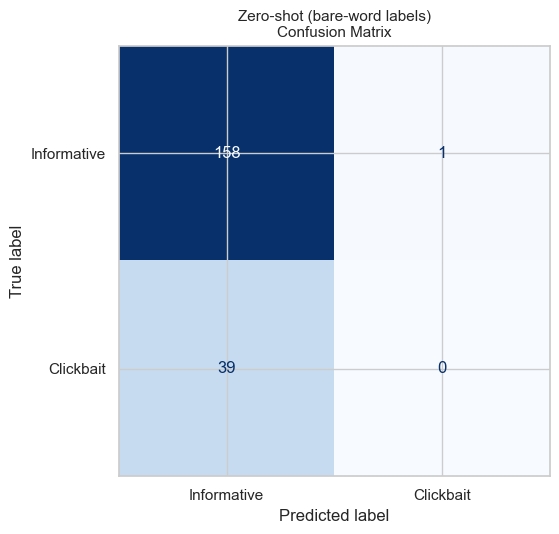

In [3]:
cm = standard["confusion_matrix"]
labels = ["Informative", "Clickbait"]
disp = ConfusionMatrixDisplay(confusion_matrix=pd.DataFrame(cm).values, display_labels=labels)
fig, ax = plt.subplots(figsize=(6, 5.5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Zero-shot (bare-word labels)\nConfusion Matrix", fontsize=11)
plt.tight_layout()
plt.savefig("zeroshot_confusion_matrix.png", dpi=150)
plt.show()

## Robustness check: does candidate-label phrasing matter?

The near-total collapse above (Clickbait precision/recall both 0.000 — the
model predicted Clickbait for essentially 1 of 198 headlines) is a striking
result, and striking results deserve a sanity check before being reported
at face value. Bare slang words like "clickbait" may simply carry weak,
inconsistent entailment signal for an NLI model, independent of whether the
*task* is learnable zero-shot at all. Re-running the identical test set with
richer, more descriptive candidate labels isolates that question.

In [4]:
rich = results["standard_split_rich_labels"]
rich_report_df = pd.DataFrame(rich["classification_report"]).T.round(3)
print(f"Candidate labels: {rich['candidate_labels']}")
print(f"Accuracy: {rich['accuracy']:.3f}")
print(f"Macro F1: {rich['macro_f1']:.3f}")
print(f"Clickbait precision: {rich['clickbait_precision']:.3f}")
print(f"Clickbait recall: {rich['clickbait_recall']:.3f}")
print()
rich_report_df

Candidate labels: ['a sensationalized clickbait headline designed to provoke curiosity', 'a factual, informative news headline']
Accuracy: 0.788
Macro F1: 0.651
Clickbait precision: 0.457
Clickbait recall: 0.410



,precision,recall,f1-score,support
Informative,0.859,0.881,0.870,159.000
Clickbait,0.457,0.410,0.432,39.000
accuracy,0.788,0.788,0.788,0.788
macro avg,0.658,0.645,0.651,198.000
weighted avg,0.780,0.788,0.783,198.000


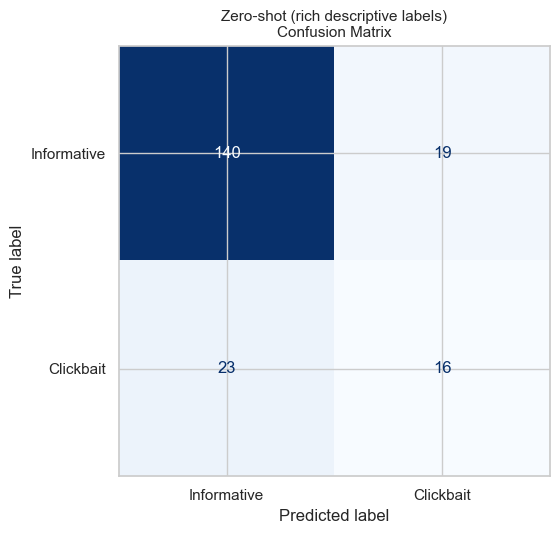

In [5]:
cm_rich = rich["confusion_matrix"]
disp = ConfusionMatrixDisplay(confusion_matrix=pd.DataFrame(cm_rich).values, display_labels=labels)
fig, ax = plt.subplots(figsize=(6, 5.5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Zero-shot (rich descriptive labels)\nConfusion Matrix", fontsize=11)
plt.tight_layout()
plt.savefig("zeroshot_rich_confusion_matrix.png", dpi=150)
plt.show()

## Per-outlet breakdown (full dataset, bare-word labels)

Zero-shot was never trained on any of this data, so unlike Stage 3/4's
held-out-outlet check (which retrains per outlet), this is simply the same
frozen model evaluated across every outlet at once — a natural "generalizes
to everything, because it was fit to nothing" comparison point.

In [6]:
per_outlet_results

,outlet,source_style,n,accuracy,macro_f1,clickbait_recall
0,citinewsroom,credible,154,0.961,0.490,0.0
1,ghpage,clickbait_heavy,164,0.543,0.352,0.0
2,gna,credible,155,0.987,0.497,0.0
3,graphic,credible,35,0.943,0.485,0.0
4,myjoyonline,credible,151,0.967,0.492,0.0
5,yen,clickbait_heavy,166,0.765,0.433,0.0
6,zionfelix,clickbait_heavy,165,0.588,0.370,0.0


In [7]:
per_outlet_results.groupby("source_style")[["accuracy", "macro_f1", "clickbait_recall"]].mean().round(3)

,accuracy,macro_f1,clickbait_recall
source_style,,,
clickbait_heavy,0.632,0.385,0.0
credible,0.964,0.491,0.0


## Three-way comparison

Stage 3 and Stage 4 numbers hardcoded from their own executed notebooks —
all three (four, counting the zero-shot label-phrasing variant) evaluate on
the identical seed=42 test set.

In [8]:
comparison = pd.DataFrame(
    {
        "baseline (TF-IDF+LR)": {"accuracy": 0.737, "macro_f1": 0.647, "clickbait_precision": 0.390, "clickbait_recall": 0.590},
        "transformer (DistilBERT)": {"accuracy": 0.783, "macro_f1": 0.714, "clickbait_precision": 0.468, "clickbait_recall": 0.744},
        "zero-shot (bare labels)": {
            "accuracy": standard["accuracy"],
            "macro_f1": standard["macro_f1"],
            "clickbait_precision": standard["clickbait_precision"],
            "clickbait_recall": standard["clickbait_recall"],
        },
        "zero-shot (rich labels)": {
            "accuracy": rich["accuracy"],
            "macro_f1": rich["macro_f1"],
            "clickbait_precision": rich["clickbait_precision"],
            "clickbait_recall": rich["clickbait_recall"],
        },
    }
).round(3)
comparison

,baseline (TF-IDF+LR),transformer (DistilBERT),zero-shot (bare labels),zero-shot (rich labels)
accuracy,0.737,0.783,0.798,0.788
macro_f1,0.647,0.714,0.444,0.651
clickbait_precision,0.390,0.468,0.000,0.457
clickbait_recall,0.590,0.744,0.000,0.410


## Summary

**The literal proposal spec (bare-word candidate labels) fails almost
completely as a classifier.** Clickbait precision and recall both land at
0.000 -- the model predicted Clickbait for essentially 1 of 198 headlines.
The 0.798 accuracy this produces is entirely an artifact of the ~80/20 class
imbalance (identical to the exact failure mode Stage 3's *unweighted*
baseline showed) -- it is not evidence the model "got the task right" 80% of
the time, and accuracy alone would badly misrepresent this result.

**But that near-total collapse is substantially a label-wording artifact,
not a hard capability ceiling.** Swapping "clickbait"/"informative" for
richer descriptive phrases -- with zero other changes, same model, same
test set -- lifts Clickbait recall from 0.000 to 0.410 and macro F1 from
0.444 to 0.651, landing *ahead of* Stage 3's baseline macro F1 (0.647). An
NLI-based zero-shot classifier is fundamentally sensitive to how the
candidate labels are phrased as hypotheses, and "clickbait" specifically
appears to be a weak, low-entailment-signal token for this model -- worth
flagging explicitly in the paper as a methodological finding in its own
right, not just a footnote.

**Even at its best, zero-shot still falls short of fine-tuning.** Rich-label
zero-shot's macro F1 (0.651) is essentially tied with the TF-IDF baseline
(0.647) but clearly behind fine-tuned DistilBERT (0.714), and its Clickbait
recall (0.410) is well below both the baseline (0.590) and DistilBERT
(0.744). This is exactly the finding the proposal's §4.3 anticipated --
"the comparison with the fine-tuned model reveals how much value the
annotated dataset adds" -- and the answer is: a great deal. General
pretrained world knowledge about what "clickbait" means gets a zero-shot
model to roughly classical-baseline performance at best; task-specific
fine-tuning on the Ghana-context annotated data is what actually closes the
gap to a genuinely useful classifier.

**Per-outlet, zero-shot (bare labels) never predicts Clickbait for any
outlet** -- accuracy tracks each outlet's base rate almost exactly (highest
on the credible outlets, which have the fewest actual Clickbait headlines to
miss). This isn't a generalization result so much as confirmation that the
model made essentially one decision for the entire dataset.

**Inference was fast** -- under 4 seconds for the 198-headline test set on
a T4, consistent with there being no training step at all.

**Three-way comparison, final:**

| | Accuracy | Macro F1 | Clickbait P | Clickbait R |
|---|---|---|---|---|
| Baseline (TF-IDF+LR) | 0.737 | 0.647 | 0.390 | 0.590 |
| **Fine-tuned DistilBERT** | **0.783** | **0.714** | **0.468** | **0.744** |
| Zero-shot (bare labels) | 0.798* | 0.444 | 0.000 | 0.000 |
| Zero-shot (rich labels) | 0.788 | 0.651 | 0.457 | 0.410 |

*Zero-shot's raw accuracy numbers are misleading here (majority-class
collapse) -- macro F1 and Clickbait recall/precision are the metrics that
actually reflect classifier quality on this dataset. Fine-tuned DistilBERT
is the clear winner on every metric that matters.